<style>
    #top {
        /* two dimensional layout (rows and columns) */
        display: grid;
        /* three columns with automatic sizing for each childrens */
        grid-template-columns: auto auto auto
    }

    #top a {
        /* space between text and background color border */
        padding: 10px;
        background-color: blue;
        color: white;
        /* remove default underlines from href */
        text-decoration: none
    }

    /* absolute inline (row) positioning inside grid */
    #top a:first-child {
        justify-self: start
    }
    #top a:last-child {
        justify-self: end
    }

    #top a:hover {
        background-color: darkblue
    }
</style>

<div id="top">
    <a href="../notebook/">Previous</a>
    <h2 style="margin: 0; text-align: center;">Section 1 | Initial Data Analysis</h2>
    <a href="../notebook/2_exploratory-data-analysis.ipynb">Next</a>
</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from feature_engine.imputation import DropMissingData
from notebook_helpers import ID_AUTO_MPG, data_inspect, data_raw_etl, match_transformer
from pyampute.exploration.mcar_statistical_tests import MCARTest

### Data Specification

*The first step in data analysis is to set out a full and detailed [specification](https://en.wikipedia.org/wiki/Data_preparation#Data_specification) of the format of each data field and what the entries mean. This especially take careful account of a full understanding of the information—and any gaps available—in the source data.*

#### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Features | 7 |
| Data Types | Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Categorical, Integer |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by Quinlan (1993) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes (Quinlan, 1993).

#### Data ETL

* *[Extract, transform, load (ETL)](https://en.wikipedia.org/wiki/Extract,_transform,_load) is a three-phase computing process where data is extracted from an input source, transformed (to the appropriate format), and loaded into an output data container—or in this case, a variable instance.*
* *The table below displays 5 sample rows from the dataset which represents the ETL result.*

In [2]:
# fetch raw dataset
data = pd.DataFrame(data_raw_etl(ID_AUTO_MPG))

# show dataset samples
n_samples = 5
data.sample(n=n_samples)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
360,145.0,6,76.0,3160,19.6,81,2,30.7
363,231.0,6,110.0,3415,15.8,81,1,22.4
115,350.0,8,145.0,4082,13.0,73,1,15.0
350,105.0,4,63.0,2215,14.9,81,1,34.7
200,250.0,6,78.0,3574,21.0,76,1,18.0


* Each row in the dataframe represents a single instance from the car samples.
* The columns in the dataframe are variables that represent the diversity of each sample.
    * Some columns act as *features*, which are the independent variables used as input to a machine learning model, and
    * The first column is the *target*, which is the variable that corresponds to the input data.
* *The `car_name` column is not included in the fetching process provided by the UCI ML Repository, but it can be accessed by downloading the raw data from the [source URL](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) and opening the `auto-mpg.data` file.*

#### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | _Weight**_ | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | _modulo 100**_ | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type* | - | <center> No </center> |

***Diasumsikan sebagai curb weight dan car model year in the nineteen-hundreds (19xx) berdasarkan observasi terhadap sampel dataset*
</div>



Based on these descriptions and prior to observing the complete samples of Auto MPG dataset, it stands to reason for including all of these potentially informative feature variables in predicting target variable `mpg` as the main objective of this project.

### Data Inspection

In [3]:
# perform initial inspection on dataset
data_inspect(data)

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* The `dtype` column shows the data types in `data_train`, all of which are `float` and `int`:
    * These data types represent the random `sample` shown for each variable. For example, `mpg` contains decimal values such as `17.5`.
    * `float` indicates a numerical continuous variable, while `int` indicates a numerical discrete variable.
        * The true nature of the `weight` variable is conceptually *continuous*—even if recorded as whole numbers—since it varies smoothly in reality and the measurement resolution in this case is arbitrary.
        * Notably, the target variable `mpg` is at the *ratio* level; a true zero exists for this variable, which represents the absence of any fuel efficiency.
        * Domain knowledge indicates that the `origin` variable has an **invalid data type** and should instead be [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* In general, no invalid data issues were detected:
    * The value ranges shown in the `min` and `max` columns, according to domain knowledge, represent valid, reasonable, and realistic values for the car samples.
    * For example, in the `displacement` column, a car's engine displacement can range from `70.0` to `455.0` cubic inches.
* The data inspection process also includes detection of `duplicated` and `missing` data:
    * No duplicated data were detected, as shown by the `duplicated` column values being `0` across all variables, but
    * **Missing data** was detected in the `horsepower` variable:
        * As shown in the `missing` column, the `horsepower` variable has a value of `6`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.

#### Invalid Data Type

In [4]:
# encode selected variables in dataset to Pandas' "categorical" data type
invalid_column = "origin"
transformer = match_transformer(invalid_column)
data_matched = pd.DataFrame(
    transformer.fit_transform(data),
    columns=transformer.get_feature_names_out()
)

The `origin` variable, with a nominal data type, is also part of the categorical data type family. Therefore, the `MatchCategories()` transformer can be used to convert this variable into a suitable categorical representation for later modeling steps.

#### Missing Data

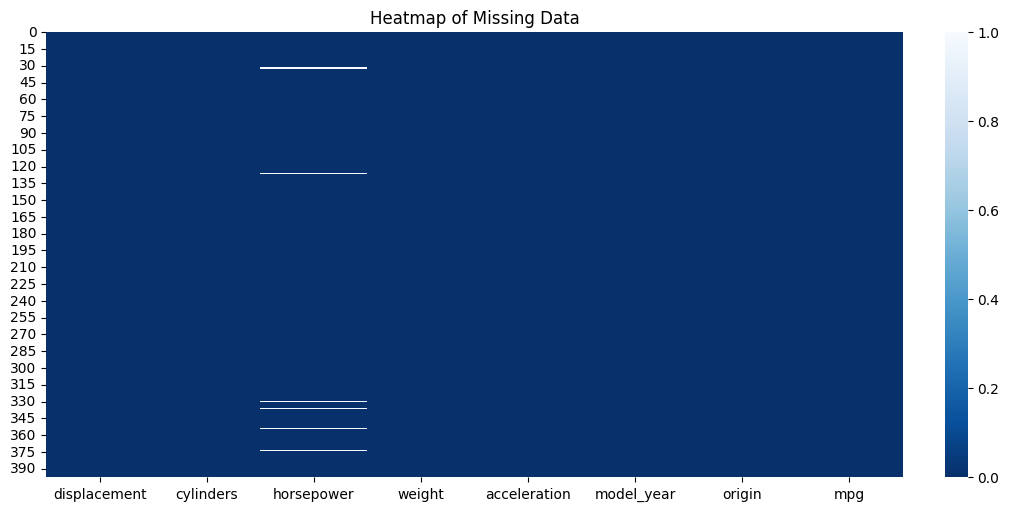

In [5]:
# visualize missing data pattern
width, height = 10, 5
plt.figure(figsize=(width, height), layout="constrained")

sns.heatmap(
    data_matched.isna().sort_index(),
    cmap="Blues_r" # reverse color map for better visibility
)
plt.title("Heatmap of Missing Data")
plt.show()

*The heatmap above shows:*
* *The white lines in the `horsepower` column represent the missing values in that column, and*
* *The `y` axis shows the location (index) of the missing values within the data.*

From this visualization, it can be interpreted that:
* The missing data are located at random positions in `horsepower`; and
* The missing data are separated from one another and do not form a clustered or patterned structure.

In [6]:
# slice missing data in dataset
missing_column = "horsepower"
data_matched[data_matched[missing_column].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


*The dataframe above shows:*
* *Samples with missing values in `horsepower`,*
* *Values of the other variables for the rows with missing data, and*
* *The indices of the missing data in the dataset.*

A priori, it can be concluded that:
* There is no indication that the missing data are dependent on any other variable.
* For example, in the `displacement` column, the missing data have a wide range of `displacement` values.

In [7]:
# access p-value from Little's MCAR test results
mcar = MCARTest("little")
data_encoded = pd.get_dummies( # convert categorical variable to numerical for calculating test statistic 
    data_matched,
    columns=[invalid_column],
    drop_first=True,
    dtype=int
)
pvalue = mcar.little_mcar_test(data_encoded)

*A brief explanation for Little's MCAR Test is as follows (Little, 1988):*
* *A statistical hypothesis test for Missing Completely At Random (MCAR).*
    * *Null hypothesis: the data is MCAR*
    * *Alternative hypothesis: the data is not MCAR*
* *The method used is a chi-square test on the entire dataset; it compares the group of observations with missing values against the group without missing values to determine whether there is a significant relationship between the two groups.*

In [8]:
# evaluate Little's MCAR test results
alpha = 0.05
decision = "Reject H0" if pvalue <= alpha else "Accept H0"

df_mcar = pd.DataFrame({
    "pvalue": [pvalue],
    "decision": [decision]
}, index=["result"])
df_mcar.transpose()

,result
pvalue,0.372115
decision,Accept H0


* The visual and tabular observations above provide the inference that the missing data are MCAR.
* When data are MCAR, there is absolutely no relationship between the missing data and any other values, observed or missing, within the dataset.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than others.
* If values for observations are missing completely at random, then excluding those cases would not bias the inferences made.

In [9]:
# discard missing data from dataset
transformer = DropMissingData()
data_cleaned = pd.DataFrame(
    transformer.fit_transform(data_matched),
    columns=transformer.get_feature_names_out()
)

* *The transformation used on `data_train` is also applied to [subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether they are `data_test` or data in a production system.*
* *The removal process uses the `DropMissingData()` transformer because it is compatible with the Scikit-learn pipeline that will be used in the later stage of this project.*

#### Inspection Summary

In [10]:
# perform final inspection on cleaned dataset
pd.DataFrame({
    "dtype": data_cleaned.dtypes,
    "missing": data_cleaned.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


<div align="center">

| Anomaly | Solution |
| --- | --- |
| Invalid Data Type | The `origin` variable, which was previously an integer, was successfully converted to the appropriate `category` data type |
| Missing Data | No more missing values detected in the Auto MPG dataset |

</div>

In [ ]:
# setup filesystem path for cleaned dataset
notebook_dir = Path.cwd()
data_dir = notebook_dir.parent / "data"
data_dir.mkdir(exist_ok=True)
data_path = data_dir / "data_cleaned.csv"

# write cleaned dataset to .csv file
try:
    pd.DataFrame(data_cleaned).to_csv(data_path)
    print ("CSV export successful")

except OSError as error:
    print(f"CSV export failed: {type(error).__name__}: {error}")

CSV export successful


<style>
  .back-to-top {
    /* use one dimensional layout (rows by default) */
    display: flex;
    /* align anchor items horizontally */
    justify-content: center
  }

  .back-to-top a {
    padding: 10px;
    background-color: blue;
    color: white;
    text-decoration: none
  }

  .back-to-top a:hover {
    background-color: darkblue
  }
</style>

<div class="back-to-top">
  <a href="#top">Back to Top</a>
</div>